### Lab 05 – Izhikevich Spiking Neuron Model

In this lab, you will implement the Izhikevich neuron model and simulate different biological firing patterns such as regular spiking, fast spiking, and bursting.

You will complete missing code inside `models/izhikevich.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from config import DT, T_TOTAL, I_CONST
from config import REGULAR_SPIKING, FAST_SPIKING, BURSTING
from models.izhikevich import simulate_izhikevich
from utils.plotting import plot_trace, plot_multiple_traces
from utils.metrics import firing_rate, isi, spike_count

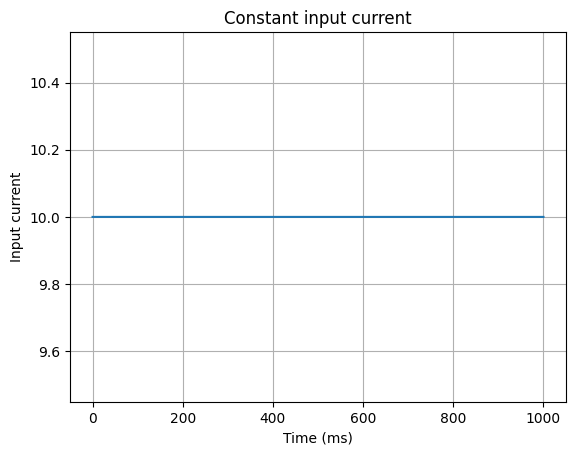

In [2]:
t = np.arange(0, T_TOTAL + DT, DT)
I = np.ones_like(t) * I_CONST

plt.figure()
plt.plot(t, I)
plt.title("Constant input current")
plt.xlabel("Time (ms)")
plt.ylabel("Input current")
plt.grid(True)
plt.show()

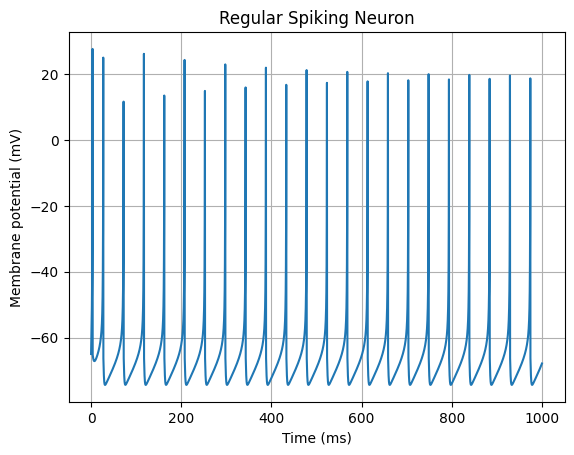

Spike count: 23
Firing rate (Hz): 23.0


In [3]:
# Run regular spiking neuron
params = REGULAR_SPIKING
v_rs, u_rs, sp_rs = simulate_izhikevich(I, t, **params)

plot_trace(t, v_rs, "Regular Spiking Neuron", "Membrane potential (mV)")
print("Spike count:", spike_count(sp_rs))
print("Firing rate (Hz):", firing_rate(sp_rs, 0, T_TOTAL))

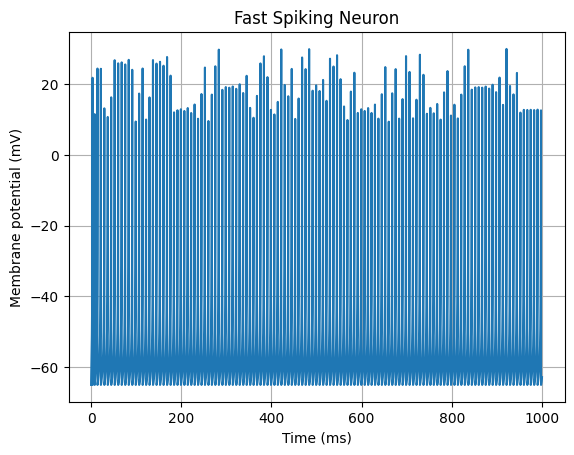

Spike count: 131
Firing rate (Hz): 131.0


In [4]:
# TODO 3:
# Simulate the fast spiking neuron using FAST_SPIKING parameters
# Plot membrane potential
# Print spike count and firing rate

params = FAST_SPIKING
v_fs, u_fs, sp_fs = simulate_izhikevich(I, t, **params)

plot_trace(t, v_fs, "Fast Spiking Neuron", "Membrane potential (mV)")
print("Spike count:", spike_count(sp_fs))
print("Firing rate (Hz):", firing_rate(sp_fs, 0, T_TOTAL))

# Answer: the fast spiking neuron fires many more spikes than the regular
# spiking neuron, because a = 0.1 makes the recovery variable u fast.


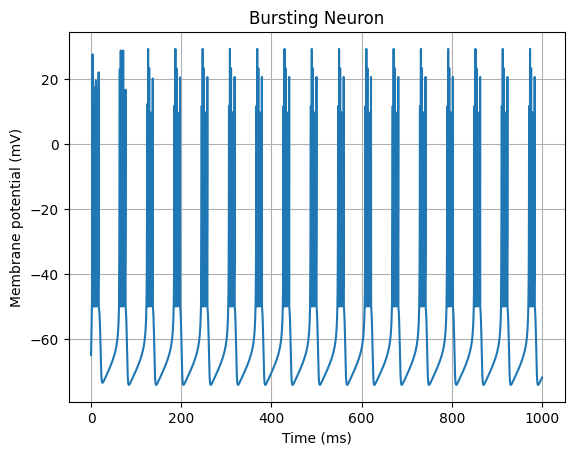

Spike count: 87
Firing rate (Hz): 87.0


In [5]:
# TODO 4:
# Simulate the bursting neuron using BURSTING parameters
# Plot membrane potential
# Print spike count and firing rate

params = BURSTING
v_bs, u_bs, sp_bs = simulate_izhikevich(I, t, **params)

plot_trace(t, v_bs, "Bursting Neuron", "Membrane potential (mV)")
print("Spike count:", spike_count(sp_bs))
print("Firing rate (Hz):", firing_rate(sp_bs, 0, T_TOTAL))

# Answer: the spikes come in small groups (bursts) with gaps between them,
# because c = -50 resets the voltage to a higher value.


In [6]:
# TODO 5:
# Compute and print inter-spike intervals for the regular spiking neuron

isi_rs = isi(sp_rs)

print("Inter-spike intervals (ms):", isi_rs)
print("Number of ISIs:", len(isi_rs))
print("Mean ISI (ms):", np.mean(isi_rs))

# Answer: the ISIs are almost constant (about 45 ms), so the regular spiking
# neuron fires in a regular, periodic way.


Inter-spike intervals (ms): [23.7 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1
 45.1 45.1 45.1 45.1 45.1 45.1 45.1 45.1]
Number of ISIs: 22
Mean ISI (ms): 44.12727272727273


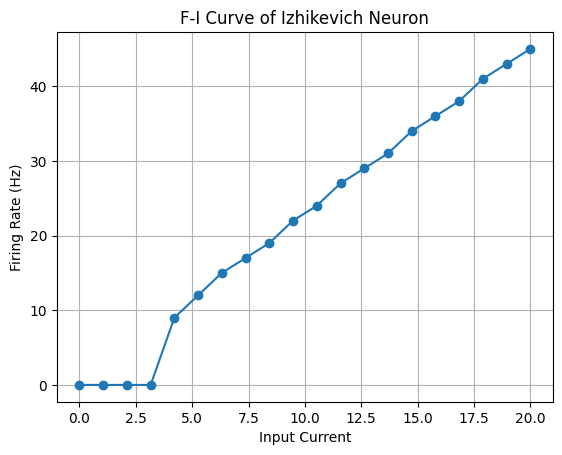

Currents: [ 0.          1.05263158  2.10526316  3.15789474  4.21052632  5.26315789
  6.31578947  7.36842105  8.42105263  9.47368421 10.52631579 11.57894737
 12.63157895 13.68421053 14.73684211 15.78947368 16.84210526 17.89473684
 18.94736842 20.        ]
Rates (Hz): [0.0, 0.0, 0.0, 0.0, 9.0, 12.0, 15.0, 17.0, 19.0, 22.0, 24.0, 27.0, 29.0, 31.0, 34.0, 36.0, 38.0, 41.0, 43.0, 45.0]


In [7]:
# TODO 6 - F-I Curve Analysis
# Use the Regular Spiking neuron parameters.
# Vary the input current from:

# 0 -> 20

# For each current value:
# simulate the neuron
# compute the firing rate
# store the result
# Plot the F-I curve.
currents = np.linspace(0, 20, 20)
rates = []

for I_value in currents:
    
    # Create input current
    I = np.ones_like(t) * I_value
    
    # Run neuron simulation
    v, u, spikes = simulate_izhikevich(I, t, **REGULAR_SPIKING)
    
    # TODO:
    # compute firing rate using spike_times
    
    rate = firing_rate(spikes, 0, T_TOTAL)
    
    rates.append(rate)

# Plot F-I curve
plt.figure()
plt.plot(currents, rates, marker='o')
plt.xlabel("Input Current")
plt.ylabel("Firing Rate (Hz)")
plt.title("F-I Curve of Izhikevich Neuron")
plt.grid(True)
plt.show()

print("Currents:", currents)
print("Rates (Hz):", rates)

# Answer: the neuron stays silent for small currents, and after the threshold
# current the firing rate grows almost linearly with the input current.

# Put the constant current back for the other cells
I = np.ones_like(t) * I_CONST


In [8]:
## TODO 7 - Short Comparison (3-5 sentences)

# Compare the Izhikevich neuron with the LIF neuron from Lab 4.

# Discuss:
# - biological realism
# - number of firing patterns
# - computational cost
# - when each model is useful

# Answer:
# 1. The Izhikevich model is more biologically realistic than LIF, because it
#    has a real spike shape and a recovery variable u, while LIF only charges
#    up and is reset by hand.
# 2. The Izhikevich model can produce many firing patterns (regular spiking,
#    fast spiking, bursting, adaptation) just by changing a, b, c, d, but the
#    LIF neuron can only do simple regular spiking.
# 3. LIF is cheaper because it has only one equation, while Izhikevich has two
#    equations, but Izhikevich is still very cheap compared to Hodgkin-Huxley.
# 4. LIF is useful for large and simple networks or for quick theory work, and
#    Izhikevich is useful when we need realistic firing patterns in large
#    spiking network simulations.
